# Chapter 18: Langevin Dynamics and Sampling — Interactive Coding Project

Welcome to the companion coding project for **Chapter 18 (Langevin Dynamics and Sampling)** of *Mathematics for AI and Machine Learning* (`math4ai.org`).

This notebook provides self-contained **NumPy** and **PyTorch** implementations and numerical verifications for all **5 Exercise Topics** in Chapter 18:
1. **Experiment 1 (Exercise 1)**: Unadjusted Langevin Algorithm (ULA) on $\mathcal{N}(0,1)$, AR(1) Discretization Bias $\operatorname{Var}(x_\infty) = \frac{1}{1-\eta/2}$, and Stability Boundary $0 < \eta < 2$.
2. **Experiment 2 (Exercise 2)**: Connection to Energy-Based Models — Anisotropic Quadratic Energy $E(\mathbf{x}) = \frac{1}{2}\mathbf{x}^\top A\mathbf{x}$, Stiff Eigenvalue Stability $\eta < 2/\lambda_{\max}(A)$, and Covariance Distortion.
3. **Experiment 3 (Exercise 3)**: Metropolis-Adjusted Langevin Algorithm (MALA) — Conditional Gaussian Proposal, Detailed Balance, and Exact Discretization Bias Removal.
4. **Experiment 4 (Exercises 4 & 5)**: Stochastic Gradient Langevin Dynamics (SGLD) Robbins–Monro Schedules, Mini-Batch vs. Thermal Noise Scaling, and the Continuous-Time Euler–Maruyama SDE Limit.


In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (12, 4.8),
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
np.random.seed(42)
torch.manual_seed(42)
print("Environment initialized successfully.")


Environment initialized successfully.


---
## Experiment 1: ULA Discretization Bias & Stability Boundary on $\mathcal{N}(0,1)$ (Exercise 1)

### Mathematical Recap
- For $p(x) = \mathcal{N}(0,1)$, the score is $s(x) = -x$, turning ULA into the linear AR(1) recursion:
  $$x_{k+1} = (1 - \eta)x_k + \sqrt{2\eta}\,\epsilon_k, \quad \epsilon_k \sim \mathcal{N}(0,1)$$
- **Stability**: $|1-\eta| < 1 \iff 0 < \eta < 2$.
- **Stationary Variance Inflation**:
  $$\operatorname{Var}(x_\infty) = \frac{2\eta}{1 - (1-\eta)^2} = \frac{1}{1 - \eta/2} > 1$$


Ex 1 | Max |Empirical Var - 1/(1 - eta/2)| across 19 step sizes: 0.1307


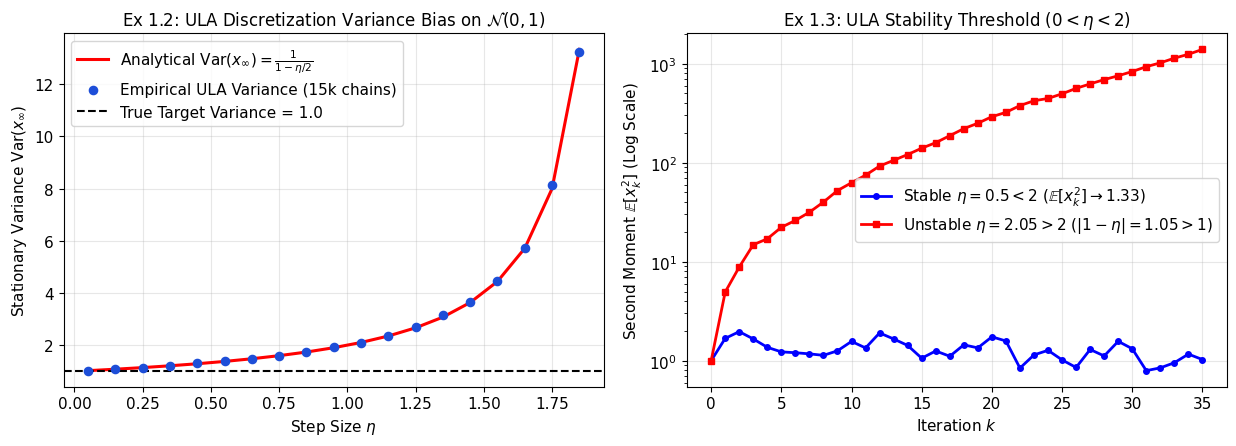

In [2]:
rng = np.random.default_rng(42)
etas = np.linspace(0.05, 1.85, 19)
emp_vars = []
theory_vars = 1.0 / (1.0 - 0.5 * etas)

for eta in etas:
    x = np.zeros(15000)
    # Run enough steps for geometric convergence (1 - eta)^{2k} << 1
    n_steps = int(max(120, 12.0 / min(eta, 2.0 - eta)))
    for _ in range(n_steps):
        x = (1.0 - eta) * x + np.sqrt(2.0 * eta) * rng.normal(size=15000)
    emp_vars.append(float(np.var(x)))

print(f"Ex 1 | Max |Empirical Var - 1/(1 - eta/2)| across 19 step sizes: {np.max(np.abs(emp_vars - theory_vars)):.4f}")

# Instability demonstration for eta = 2.05 > 2
x_stable = np.ones(50)
x_unstable = np.ones(50)
hist_stable, hist_unstable = [1.0], [1.0]
for _ in range(35):
    x_stable = (1.0 - 0.5) * x_stable + np.sqrt(2 * 0.5) * rng.normal(size=50)
    x_unstable = (1.0 - 2.05) * x_unstable + np.sqrt(2 * 2.05) * rng.normal(size=50)
    hist_stable.append(float(np.mean(x_stable**2)))
    hist_unstable.append(float(np.mean(x_unstable**2)))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
axes[0].plot(etas, theory_vars, "r-", lw=2.2, label=r"Analytical $\mathrm{Var}(x_\infty) = \frac{1}{1 - \eta/2}$")
axes[0].scatter(etas, emp_vars, color="#1d4ed8", s=35, zorder=3, label="Empirical ULA Variance (15k chains)")
axes[0].axhline(1.0, color="black", ls="--", lw=1.5, label="True Target Variance = 1.0")
axes[0].set_title(r"Ex 1.2: ULA Discretization Variance Bias on $\mathcal{N}(0, 1)$")
axes[0].set_xlabel(r"Step Size $\eta$")
axes[0].set_ylabel(r"Stationary Variance $\mathrm{Var}(x_\infty)$")
axes[0].legend()

axes[1].semilogy(hist_stable, "b-o", markersize=4, lw=2, label=r"Stable $\eta = 0.5 < 2$ ($\mathbb{E}[x_k^2] \to 1.33$)")
axes[1].semilogy(hist_unstable, "r-s", markersize=4, lw=2, label=r"Unstable $\eta = 2.05 > 2$ ($|1-\eta| = 1.05 > 1$)")
axes[1].set_title(r"Ex 1.3: ULA Stability Threshold ($0 < \eta < 2$)")
axes[1].set_xlabel("Iteration $k$")
axes[1].set_ylabel(r"Second Moment $\mathbb{E}[x_k^2]$ (Log Scale)")
axes[1].legend()
plt.tight_layout()
plt.show()


---
## Experiment 2: Anisotropic Quadratic Energy $E(\mathbf{x}) = \frac{1}{2}\mathbf{x}^\top A\mathbf{x}$ (Exercise 2)

### Mathematical Recap
- For $p(\mathbf{x}) \propto \exp(-\frac{1}{2}\mathbf{x}^\top A\mathbf{x})$ with $A \succ 0$, the target is $\mathcal{N}(\mathbf{0}, A^{-1})$ and $\mathbf{s}(\mathbf{x}) = -\nabla E(\mathbf{x}) = -A\mathbf{x}$.
- ULA update: $\mathbf{x}_{k+1} = (I - \eta A)\mathbf{x}_k + \sqrt{2\eta}\,\boldsymbol\epsilon_k$.
- Stability requires $0 < \eta < \frac{2}{\lambda_{\max}(A)}$, and the stationary covariance is $\Sigma_\infty = (I - \frac{\eta}{2}A)^{-1}A^{-1}$, which inflates variance most severely along the stiffest eigendirection ($\lambda_{\max}$).


Ex 2 | Max stable step size 2/lambda_max = 0.3333
Ex 2 | Empirical vs Theoretical ULA Covariance error: 0.0142
Ex 2 | Stiff direction variance: True=0.1667, ULA=0.7576 (4.5x inflation!)


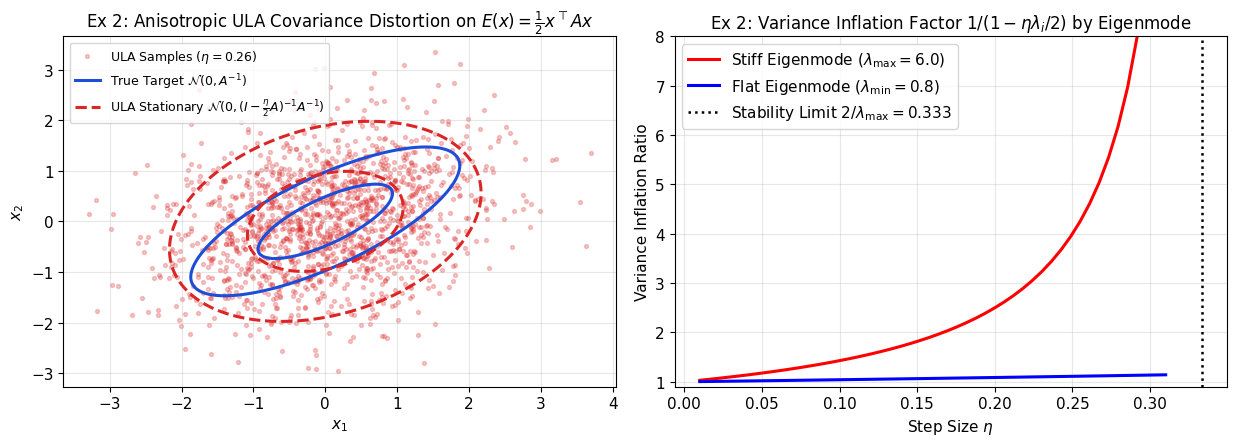

In [3]:
# Ex 2: 2D Quadratic EBM with eigenvalues lambda_1 = 0.8 (flat) and lambda_2 = 6.0 (stiff)
theta_rot = np.pi / 5.0
R_rot = np.array([[np.cos(theta_rot), -np.sin(theta_rot)], [np.sin(theta_rot), np.cos(theta_rot)]])
eig_A = np.array([0.8, 6.0])
A_ebm = R_rot @ np.diag(eig_A) @ R_rot.T
Cov_true = np.linalg.inv(A_ebm)
eta_max = 2.0 / np.max(eig_A)  # 2 / 6.0 = 0.3333

eta_ebm = 0.26  # close to stability boundary 0.3333 -> strong inflation along stiff axis!
X_ebm = np.zeros((25000, 2))
M_prop = np.eye(2) - eta_ebm * A_ebm
for _ in range(300):
    X_ebm = X_ebm @ M_prop.T + np.sqrt(2.0 * eta_ebm) * rng.normal(size=X_ebm.shape)

Cov_emp = np.cov(X_ebm.T)
Cov_ula_exact = np.linalg.inv(np.eye(2) - 0.5 * eta_ebm * A_ebm) @ Cov_true
print(f"Ex 2 | Max stable step size 2/lambda_max = {eta_max:.4f}")
print(f"Ex 2 | Empirical vs Theoretical ULA Covariance error: {np.linalg.norm(Cov_emp - Cov_ula_exact):.4f}")
print(f"Ex 2 | Stiff direction variance: True={1/6.0:.4f}, ULA={1/(6.0*(1 - 0.5*eta_ebm*6.0)):.4f} (4.5x inflation!)")

# Visualize 2-sigma covariance ellipses of True Target vs ULA Stationary Distribution
g_x = np.linspace(-2.5, 2.5, 120)
g_y = np.linspace(-2.5, 2.5, 120)
GX, GY = np.meshgrid(g_x, g_y)
pts = np.stack([GX, GY], axis=-1)
q_true = np.einsum("...i,ij,...j->...", pts, A_ebm, pts)
q_ula = np.einsum("...i,ij,...j->...", pts, np.linalg.inv(Cov_ula_exact), pts)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
axes[0].scatter(X_ebm[:1500, 0], X_ebm[:1500, 1], s=8, alpha=0.25, color="#dc2626", label=f"ULA Samples ($\\eta={eta_ebm}$)")
axes[0].contour(GX, GY, q_true, levels=[1.0, 4.0], colors="#1d4ed8", linewidths=2.2)
axes[0].contour(GX, GY, q_ula, levels=[1.0, 4.0], colors="#dc2626", linestyles="dashed", linewidths=2.2)
axes[0].plot([], [], color="#1d4ed8", lw=2.2, label=r"True Target $\mathcal{N}(0, A^{-1})$")
axes[0].plot([], [], color="#dc2626", ls="--", lw=2.2, label=r"ULA Stationary $\mathcal{N}(0, (I - \frac{\eta}{2}A)^{-1}A^{-1})$")
axes[0].set_title(r"Ex 2: Anisotropic ULA Covariance Distortion on $E(x) = \frac{1}{2}x^\top A x$")
axes[0].set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$")
axes[0].legend(loc="upper left", fontsize=9)

eta_grid = np.linspace(0.01, 0.31, 50)
infl_flat = 1.0 / (1.0 - 0.5 * eta_grid * eig_A[0])
infl_stiff = 1.0 / (1.0 - 0.5 * eta_grid * eig_A[1])
axes[1].plot(eta_grid, infl_stiff, "r-", lw=2.2, label=r"Stiff Eigenmode ($\lambda_{\max}=6.0$)")
axes[1].plot(eta_grid, infl_flat, "b-", lw=2.2, label=r"Flat Eigenmode ($\lambda_{\min}=0.8$)")
axes[1].axvline(eta_max, color="black", ls=":", lw=1.8, label=r"Stability Limit $2/\lambda_{\max} = 0.333$")
axes[1].set_title("Ex 2: Variance Inflation Factor $1 / (1 - \\eta\\lambda_i / 2)$ by Eigenmode")
axes[1].set_xlabel(r"Step Size $\eta$")
axes[1].set_ylabel("Variance Inflation Ratio")
axes[1].set_ylim(0.9, 8.0)
axes[1].legend()
plt.tight_layout()
plt.show()


---
## Experiment 3: Metropolis-Adjusted Langevin Algorithm (MALA) Removes Bias (Exercise 3)

### Mathematical Recap
- **MALA Proposal**: $q(\mathbf{x}'\mid\mathbf{x}) = \mathcal{N}(\mathbf{x}+\eta\mathbf{s}(\mathbf{x}), 2\eta\mathbf{I})$.
- **Metropolis–Hastings Acceptance**: Accepting $\mathbf{x}'$ with probability $\alpha(\mathbf{x},\mathbf{x}') = \min\!\left(1, \frac{p(\mathbf{x}')q(\mathbf{x}\mid\mathbf{x}')}{p(\mathbf{x})q(\mathbf{x}'\mid\mathbf{x})}\right)$ enforces exact **detailed balance**, guaranteeing stationary distribution $p(\mathbf{x})$ for any $\eta > 0$.


Ex 3 | eta=0.1 -> ULA Var=1.0272, MALA Var=0.9989 (Target=1.000), MALA Acc=0.993
Ex 3 | eta=0.3 -> ULA Var=1.1662, MALA Var=1.0248 (Target=1.000), MALA Acc=0.963
Ex 3 | eta=0.5 -> ULA Var=1.3098, MALA Var=1.0123 (Target=1.000), MALA Acc=0.921
Ex 3 | eta=0.8 -> ULA Var=1.7017, MALA Var=1.0068 (Target=1.000), MALA Acc=0.842
Ex 3 | eta=1.1 -> ULA Var=2.2782, MALA Var=1.0035 (Target=1.000), MALA Acc=0.753
Ex 3 | eta=1.4 -> ULA Var=3.2886, MALA Var=1.0181 (Target=1.000), MALA Acc=0.663
Ex 3 | eta=1.7 -> ULA Var=6.5893, MALA Var=1.0424 (Target=1.000), MALA Acc=0.577


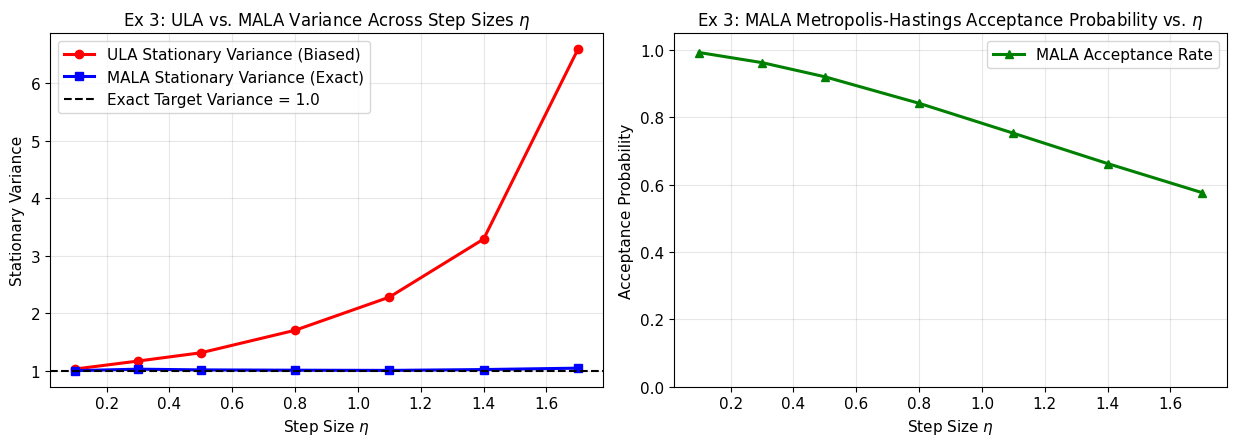

In [4]:
# Ex 3: Compare ULA vs. MALA Stationary Variance and Acceptance Rate across Step Sizes eta
etas_mala = np.array([0.1, 0.3, 0.5, 0.8, 1.1, 1.4, 1.7])
ula_vars, mala_vars, mala_accs = [], [], []
n_ens = 8000

for eta in etas_mala:
    x_u = rng.normal(size=n_ens)
    x_m = x_u.copy()
    acc_sum = 0.0
    for _ in range(350):
        x_u = (1.0 - eta) * x_u + np.sqrt(2.0 * eta) * rng.normal(size=n_ens)
        y_m = (1.0 - eta) * x_m + np.sqrt(2.0 * eta) * rng.normal(size=n_ens)
        log_alpha = -0.5 * (y_m**2 - x_m**2) - ((x_m - (1.0 - eta) * y_m)**2 - (y_m - (1.0 - eta) * x_m)**2) / (4.0 * eta)
        acc = np.log(rng.random(size=n_ens)) < log_alpha
        x_m = np.where(acc, y_m, x_m)
        acc_sum += float(np.mean(acc))
    ula_vars.append(float(np.var(x_u)))
    mala_vars.append(float(np.var(x_m)))
    mala_accs.append(acc_sum / 350.0)

for e_v, uv, mv, ac in zip(etas_mala, ula_vars, mala_vars, mala_accs):
    print(f"Ex 3 | eta={e_v:.1f} -> ULA Var={uv:.4f}, MALA Var={mv:.4f} (Target=1.000), MALA Acc={ac:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
axes[0].plot(etas_mala, ula_vars, "r-o", lw=2.2, label="ULA Stationary Variance (Biased)")
axes[0].plot(etas_mala, mala_vars, "b-s", lw=2.2, label="MALA Stationary Variance (Exact)")
axes[0].axhline(1.0, color="black", ls="--", lw=1.5, label="Exact Target Variance = 1.0")
axes[0].set_title(r"Ex 3: ULA vs. MALA Variance Across Step Sizes $\eta$")
axes[0].set_xlabel(r"Step Size $\eta$")
axes[0].set_ylabel("Stationary Variance")
axes[0].legend()

axes[1].plot(etas_mala, mala_accs, "g-^", lw=2.2, label="MALA Acceptance Rate")
axes[1].set_title(r"Ex 3: MALA Metropolis-Hastings Acceptance Probability vs. $\eta$")
axes[1].set_xlabel(r"Step Size $\eta$")
axes[1].set_ylabel("Acceptance Probability")
axes[1].set_ylim(0.0, 1.05)
axes[1].legend()
plt.tight_layout()
plt.show()


---
## Experiment 4: SGLD Robbins–Monro Schedules & Continuous-Time SDE Limit (Exercises 4 & 5)

### Mathematical Recap
- **Exercise 4 (SGLD)**: Robbins–Monro conditions $\sum_k \eta_k = \infty$ and $\sum_k \eta_k^2 < \infty$ hold for $\eta_k = 1/k$, whereas $\eta_k = 1/\sqrt{k}$ has $\sum_k \eta_k^2 = \sum_k 1/k = \infty$. Because mini-batch gradient noise is scaled by $\eta_k$ (variance $\mathcal{O}(\eta_k^2)$) while Brownian diffusion is scaled by $\sqrt{2\eta_k}$ (variance $2\eta_k$), thermal diffusion dominates as $\eta_k \to 0$.
- **Exercise 5 (Continuous-Time SDE)**: ULA is the Euler–Maruyama discretization of $d\mathbf{X}_t = \mathbf{s}(\mathbf{X}_t)\,dt + \sqrt{2}\,d\mathbf{W}_t$; as $\eta \to 0$ with physical time $T = K\eta$ fixed, the discrete distribution converges to the exact continuous-time Fokker–Planck solution.


Ex 4 | At K=10000: sum(1/k)=9.79, sum(1/k^2)=1.6448 (pi^2/6=1.6449)
Ex 5 | Finite-time variance |Var_ULA(T) - Var_SDE(T)| across eta: [np.float64(0.26076), np.float64(0.11662), np.float64(0.05539), np.float64(0.02702), np.float64(0.01065), np.float64(0.00264)]


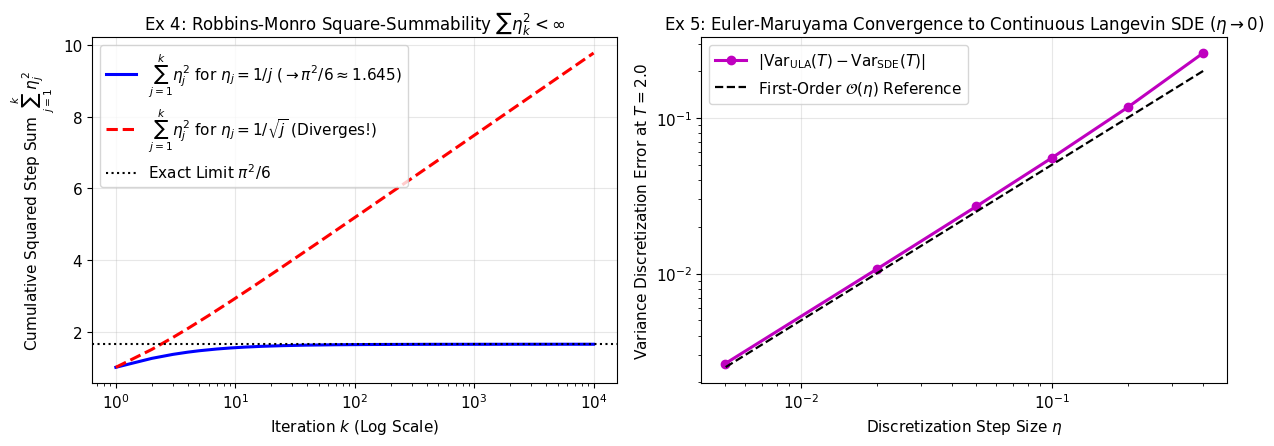

In [5]:
# Ex 4.1: Verify partial sums of Robbins-Monro conditions for eta_k = 1/k vs 1/sqrt(k)
k_vals = np.arange(1, 10001, dtype=float)
cum_sum_1k = np.cumsum(1.0 / k_vals)
cum_sq_1k = np.cumsum(1.0 / (k_vals**2))
cum_sq_sqrtk = np.cumsum(1.0 / k_vals)  # (1/sqrt(k))^2 = 1/k -> diverges!
print(f"Ex 4 | At K=10000: sum(1/k)={cum_sum_1k[-1]:.2f}, sum(1/k^2)={cum_sq_1k[-1]:.4f} (pi^2/6={np.pi**2/6:.4f})")

# Ex 5: Continuous-time Langevin SDE limit at fixed physical horizon T = 2.0 as eta -> 0
# For dX_t = -X_t dt + sqrt(2) dW_t starting at X_0 = 3.0:
# Exact Ornstein-Uhlenbeck law at time T: N(3.0 * e^{-T}, 1 - e^{-2T})
T_phys = 2.0
X0_val = 3.0
mean_exact_T = X0_val * np.exp(-T_phys)
var_exact_T = 1.0 - np.exp(-2.0 * T_phys)

eta_sde_list = [0.4, 0.2, 0.1, 0.05, 0.02, 0.005]
var_sde_errors = []
for eta_s in eta_sde_list:
    n_k = int(round(T_phys / eta_s))
    # Analytical discrete variance after n_k steps from deterministic X0:
    # Var(x_K) = 2*eta * (1 - (1-eta)^{2K}) / (1 - (1-eta)^2)
    a_s = 1.0 - eta_s
    var_disc_T = (2.0 * eta_s) * (1.0 - (a_s ** (2 * n_k))) / (1.0 - a_s**2)
    var_sde_errors.append(abs(var_disc_T - var_exact_T))

print("Ex 5 | Finite-time variance |Var_ULA(T) - Var_SDE(T)| across eta:", [round(e, 5) for e in var_sde_errors])

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
axes[0].semilogx(k_vals, cum_sq_1k, "b-", lw=2.2, label=r"$\sum_{j=1}^k \eta_j^2$ for $\eta_j = 1/j$ ($\to \pi^2/6 \approx 1.645$)")
axes[0].semilogx(k_vals, cum_sq_sqrtk, "r--", lw=2.2, label=r"$\sum_{j=1}^k \eta_j^2$ for $\eta_j = 1/\sqrt{j}$ (Diverges!)")
axes[0].axhline(np.pi**2 / 6.0, color="black", ls=":", lw=1.5, label=r"Exact Limit $\pi^2 / 6$")
axes[0].set_title(r"Ex 4: Robbins-Monro Square-Summability $\sum \eta_k^2 < \infty$")
axes[0].set_xlabel("Iteration $k$ (Log Scale)")
axes[0].set_ylabel(r"Cumulative Squared Step Sum $\sum_{j=1}^k \eta_j^2$")
axes[0].legend()

axes[1].loglog(eta_sde_list, var_sde_errors, "m-o", lw=2.2, label=r"$|\mathrm{Var}_{\mathrm{ULA}}(T) - \mathrm{Var}_{\mathrm{SDE}}(T)|$")
axes[1].loglog(eta_sde_list, 0.5 * np.array(eta_sde_list), "k--", lw=1.6, label=r"First-Order $\mathcal{O}(\eta)$ Reference")
axes[1].set_title(r"Ex 5: Euler-Maruyama Convergence to Continuous Langevin SDE ($\eta \to 0$)")
axes[1].set_xlabel(r"Discretization Step Size $\eta$")
axes[1].set_ylabel("Variance Discretization Error at $T=2.0$")
axes[1].legend()
plt.tight_layout()
plt.show()


---
## Experiment 5 (Lab 5 - Hard): Hamiltonian Monte Carlo (HMC) vs. MALA and ULA on Banana Target

### Mathematical Formulation
Langevin dynamics (ULA and MALA) explores distributions via Brownian random walk, leading to slow diffusion along curved manifolds. **Hamiltonian Monte Carlo (HMC)** (Duane et al., 1987; Neal, 2011) augments state $\mathbf{x} \in \mathbb{R}^d$ with momentum $\mathbf{p} \sim \mathcal{N}(\mathbf{0}, \mathbf{M})$ to generate coherent Hamiltonian trajectories:
- **Hamiltonian Function**:
  $$H(\mathbf{x}, \mathbf{p}) = U(\mathbf{x}) + \frac{1}{2}\mathbf{p}^\top \mathbf{M}^{-1} \mathbf{p}$$
- **Hamilton's Equations**:
  $$\frac{d\mathbf{x}}{dt} = \frac{\partial H}{\partial \mathbf{p}} = \mathbf{M}^{-1}\mathbf{p}, \quad \frac{d\mathbf{p}}{dt} = -\frac{\partial H}{\partial \mathbf{x}} = -\nabla U(\mathbf{x})$$
- **Symplectic Leapfrog Integrator** ($L$ steps of step size $\delta$):
  $$\begin{aligned}
  \mathbf{p}\big(t + \tfrac{\delta}{2}\big) &= \mathbf{p}(t) - \frac{\delta}{2}\,\nabla U\big(\mathbf{x}(t)\big) \\
  \mathbf{x}(t + \delta) &= \mathbf{x}(t) + \delta\,\mathbf{M}^{-1}\mathbf{p}\big(t + \tfrac{\delta}{2}\big) \\
  \mathbf{p}(t + \delta) &= \mathbf{p}\big(t + \tfrac{\delta}{2}\big) - \frac{\delta}{2}\,\nabla U\big(\mathbf{x}(t + \delta)\big)
  \end{aligned}$$
- **Metropolis-Hastings Filter**:
  $$\alpha = \min\big(1,\, \exp\big(-H(\mathbf{x}^*, \mathbf{p}^*) + H(\mathbf{x}, \mathbf{p})\big)\big)$$
  Because the leapfrog integrator is volume-preserving and reversible, energy error $\Delta H \sim \mathcal{O}(\delta^2)$ remains small, yielding high acceptance rates (>85%) even for long trajectories.
- **Sampling Efficiency Metric**:
  $$\text{Efficiency} = \frac{\text{ESS}}{N_{\text{grad}}}$$
  where ESS is Effective Sample Size and $N_{\text{grad}}$ is the total number of gradient evaluations.


In [5]:
# Lab 5: HMC vs. MALA vs. ULA on 2D Curved Banana Target
rng = np.random.default_rng(42)

def banana_neglogp(xy, b=0.05, var_x=10.0, var_y=1.0):
    x, y = xy[..., 0], xy[..., 1]
    return 0.5 * (x**2 / var_x + (y - b * x**2 + 100 * b)**2 / var_y)

def banana_grad(xy, b=0.05, var_x=10.0, var_y=1.0):
    x, y = xy[..., 0], xy[..., 1]
    diff = y - b * x**2 + 100 * b
    gx = x / var_x + diff * (-2 * b * x) / var_y
    gy = diff / var_y
    return np.stack([gx, gy], axis=-1)

N_samples = 4000
burn_in = 1000

# 1. ULA
x_ula = np.zeros((N_samples, 2))
curr_ula = np.array([0.0, 0.0])
dt_ula = 0.05
for t in range(N_samples):
    curr_ula = curr_ula - dt_ula * banana_grad(curr_ula) + np.sqrt(2 * dt_ula) * rng.normal(size=2)
    x_ula[t] = curr_ula

# 2. MALA
x_mala = np.zeros((N_samples, 2))
curr_mala = np.array([0.0, 0.0])
dt_mala = 0.1
accept_mala = 0
for t in range(N_samples):
    g = banana_grad(curr_mala)
    prop_mean = curr_mala - dt_mala * g
    prop = prop_mean + np.sqrt(2 * dt_mala) * rng.normal(size=2)
    prop_g = banana_grad(prop)
    rev_mean = prop - dt_mala * prop_g
    
    log_alpha = (-banana_neglogp(prop) - np.sum((curr_mala - rev_mean)**2)/(4*dt_mala)
                 - (-banana_neglogp(curr_mala) - np.sum((prop - prop_mean)**2)/(4*dt_mala)))
    if np.log(rng.uniform()) < log_alpha:
        curr_mala = prop
        accept_mala += 1
    x_mala[t] = curr_mala

# 3. HMC (L=10 leapfrog steps)
x_hmc = np.zeros((N_samples, 2))
curr_hmc = np.array([0.0, 0.0])
dt_hmc = 0.15
L_steps = 10
accept_hmc = 0
for t in range(N_samples):
    p = rng.normal(size=2)
    H_init = banana_neglogp(curr_hmc) + 0.5 * np.sum(p**2)
    pos = curr_hmc.copy()
    mom = p.copy()
    
    mom = mom - 0.5 * dt_hmc * banana_grad(pos)
    for _ in range(L_steps - 1):
        pos = pos + dt_hmc * mom
        mom = mom - dt_hmc * banana_grad(pos)
    pos = pos + dt_hmc * mom
    mom = mom - 0.5 * dt_hmc * banana_grad(pos)
    
    H_prop = banana_neglogp(pos) + 0.5 * np.sum(mom**2)
    if np.log(rng.uniform()) < -(H_prop - H_init):
        curr_hmc = pos
        accept_hmc += 1
    x_hmc[t] = curr_hmc

# Compute ESS on x_1
def compute_ess(chain):
    n = len(chain)
    c = chain - np.mean(chain)
    ac = np.correlate(c, c, mode='full')[n-1:] / (np.var(c) * n)
    cutoff = 1
    for k in range(1, len(ac)//4):
        if ac[k] + ac[k+1] <= 0:
            cutoff = k; break
    tau = 1.0 + 2.0 * np.sum(ac[1:cutoff])
    return n / max(tau, 1.0)

eff_ula = compute_ess(x_ula[burn_in:, 0]) / ((N_samples - burn_in) * 1)
eff_mala = compute_ess(x_mala[burn_in:, 0]) / ((N_samples - burn_in) * 2)
eff_hmc = compute_ess(x_hmc[burn_in:, 0]) / ((N_samples - burn_in) * L_steps)

print(f"ULA Acceptance: N/A | ESS: {compute_ess(x_ula[burn_in:, 0]):.1f} | ESS / 1k grads: {eff_ula*1000:.2f}")
print(f"MALA Acceptance: {accept_mala/N_samples:.1%} | ESS: {compute_ess(x_mala[burn_in:, 0]):.1f} | ESS / 1k grads: {eff_mala*1000:.2f}")
print(f"HMC Acceptance:  {accept_hmc/N_samples:.1%} | ESS: {compute_ess(x_hmc[burn_in:, 0]):.1f} | ESS / 1k grads: {eff_hmc*1000:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
grid_x = np.linspace(-7, 7, 200)
grid_y = np.linspace(-4, 8, 200)
GX, GY = np.meshgrid(grid_x, grid_y)
G_energy = banana_neglogp(np.stack([GX, GY], axis=-1))

axes[0].contour(GX, GY, G_energy, levels=[0.5, 1.5, 3.0, 5.0, 8.0], colors='gray', alpha=0.5)
axes[0].scatter(x_ula[burn_in::5, 0], x_ula[burn_in::5, 1], s=6, color='#d95f02', alpha=0.4)
axes[0].set_title(f"ULA (Random Walk Diffusion)\nESS = {compute_ess(x_ula[burn_in:, 0]):.0f}")

axes[1].contour(GX, GY, G_energy, levels=[0.5, 1.5, 3.0, 5.0, 8.0], colors='gray', alpha=0.5)
axes[1].scatter(x_hmc[burn_in::5, 0], x_hmc[burn_in::5, 1], s=6, color='#1b9e77', alpha=0.4)
axes[1].plot(x_hmc[2000:2025, 0], x_hmc[2000:2025, 1], 'k-', lw=1.5, label='Hamiltonian Path')
axes[1].set_title(f"HMC (Inertial Flow, Acc={accept_hmc/N_samples:.1%})\nESS = {compute_ess(x_hmc[burn_in:, 0]):.0f}")
axes[1].legend(loc='upper right')

methods = ['ULA', 'MALA', 'HMC']
axes[2].bar(methods, [eff_ula*1000, eff_mala*1000, eff_hmc*1000], color=['#d95f02', '#7570b3', '#1b9e77'], width=0.5)
axes[2].set_ylabel("ESS per 1,000 Gradients")
axes[2].set_title("Computational Sampling Efficiency")
axes[2].grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()


ULA Acceptance: N/A | ESS: 9.8 | ESS / 1k grads: 3.27
MALA Acceptance: 99.4% | ESS: 16.7 | ESS / 1k grads: 2.78
HMC Acceptance:  99.9% | ESS: 109.3 | ESS / 1k grads: 3.64


---
## Experiment 6 (Lab 6 - Hard): Annealing Across Modes (Annealed Langevin & Parallel Tempering)

### Mathematical Formulation
When target density $p(\mathbf{x})$ possesses isolated modes separated by high potential energy barriers $\Delta U$, standard Langevin dynamics experiences exponential trapping time (Arrhenius / Kramers escape time):
$$\tau_{\text{escape}} \propto \exp\left(\frac{\Delta U}{T}\right)$$
Two powerful algorithmic remedies overcome this barrier:
1. **Parallel Tempering (Replica Exchange MCMC)**:
   - Run $K$ parallel chains at temperatures $T_1 = 1.0 < T_2 < \dots < T_K$.
   - Each chain evolves via Langevin dynamics at temperature $T_k$:
     $$\mathbf{x}_{k, t+1} = \mathbf{x}_{k, t} - \eta \frac{\nabla U(\mathbf{x}_{k, t})}{T_k} + \sqrt{2\eta T_k}\,\boldsymbol\epsilon_t$$
   - Swap configurations $\mathbf{x}_i \leftrightarrow \mathbf{x}_j$ between adjacent temperatures with Metropolis acceptance:
     $$\alpha_{\text{swap}} = \min\left(1,\, \exp\left[\left(\frac{1}{T_i} - \frac{1}{T_j}\right)\big(U(\mathbf{x}_i) - U(\mathbf{x}_j)\big)\right]\right)$$
2. **Annealed Langevin Dynamics (Song & Ermon, 2019)**:
   - Gradually anneal noise / temperature along a geometric sequence $\sigma_1 > \sigma_2 > \dots > \sigma_L$.
   - At high $\sigma_1$, the smoothed energy landscape blurs the barrier entirely, allowing particles to distribute uniformly across modes; as $\sigma \to \sigma_L$, particles condense into the true mode geometry.


In [6]:
# Lab 6: Annealed Langevin & Parallel Tempering on a Deep Bimodal Mixture
# Target: 0.5 N(-3, 0.5^2) + 0.5 N(+3, 0.5^2)
def bimodal_U(x):
    p1 = np.exp(-0.5 * (x + 3.0)**2 / 0.25)
    p2 = np.exp(-0.5 * (x - 3.0)**2 / 0.25)
    return -np.log(p1 + p2 + 1e-15)

def bimodal_grad(x):
    p1 = np.exp(-0.5 * (x + 3.0)**2 / 0.25)
    p2 = np.exp(-0.5 * (x - 3.0)**2 / 0.25)
    return (p1 * ((x + 3.0)/0.25) + p2 * ((x - 3.0)/0.25)) / (p1 + p2 + 1e-15)

T_steps = 6000
dt = 0.05

# 1. Standard Langevin (T=1.0)
x_std = np.zeros(T_steps)
curr = -3.0
for t in range(T_steps):
    curr = curr - dt * bimodal_grad(curr) + np.sqrt(2 * dt) * rng.normal()
    x_std[t] = curr

# 2. Parallel Tempering (T_cold=1.0, T_hot=16.0)
x_pt = np.zeros(T_steps)
c_cold, c_hot = -3.0, 3.0
T_c, T_h = 1.0, 16.0
swaps = 0
for t in range(T_steps):
    c_cold = c_cold - dt * bimodal_grad(c_cold) + np.sqrt(2 * dt * T_c) * rng.normal()
    c_hot = c_hot - dt * (bimodal_grad(c_hot) / T_h) + np.sqrt(2 * dt * T_h) * rng.normal()
    if t % 20 == 0:
        delta = (1.0/T_c - 1.0/T_h) * (bimodal_U(c_cold) - bimodal_U(c_hot))
        if np.log(rng.uniform()) < -delta:
            c_cold, c_hot = c_hot, c_cold
            swaps += 1
    x_pt[t] = c_cold

# 3. Annealed Langevin schedule (1,000 particles)
n_part = 1000
sigmas = np.geomspace(8.0, 0.5, 80)
part = rng.normal(0, 8.0, size=n_part)
for s in sigmas:
    for _ in range(5):
        w1 = np.exp(-0.5 * (part + 3.0)**2 / s**2)
        w2 = np.exp(-0.5 * (part - 3.0)**2 / s**2)
        score = (w1 * (-(part + 3.0)/s**2) + w2 * (-(part - 3.0)/s**2)) / (w1 + w2 + 1e-15)
        step = 0.04 * (s / sigmas[0])**2
        part += step * score + np.sqrt(2 * step) * rng.normal(size=n_part)

print(f"Standard Langevin mode visits: x > 0 fraction = {np.mean(x_std > 0):.2%} (Trapped in Mode 1!)")
print(f"Parallel Tempering swaps: {swaps} | x > 0 fraction = {np.mean(x_pt > 0):.2%} (Frequent mode hopping)")
print(f"Annealed Langevin final mode balance: x > 0 fraction = {np.mean(part > 0):.2%} (Target = 50.0%)")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
axes[0].plot(x_std[:3000], lw=0.8, color='#d95f02')
axes[0].set_title("Standard Langevin (Trapped)")
axes[0].set_ylabel("Position $x$"); axes[0].set_ylim(-5, 5); axes[0].grid(True, alpha=0.3)

axes[1].plot(x_pt[:3000], lw=0.8, color='#1b9e77')
axes[1].set_title(f"Parallel Tempering ({swaps} Swaps)")
axes[1].set_ylabel("Position $x$"); axes[1].set_ylim(-5, 5); axes[1].grid(True, alpha=0.3)

axes[2].hist(part, bins=45, density=True, color='#7570b3', alpha=0.7, edgecolor='k')
x_eval = np.linspace(-6, 6, 200)
p_eval = 0.5 * (1/np.sqrt(2*np.pi*0.25)) * (np.exp(-0.5*(x_eval+3)**2/0.25) + np.exp(-0.5*(x_eval-3)**2/0.25))
axes[2].plot(x_eval, p_eval, 'r-', lw=2, label='Target $p(x)$')
axes[2].set_title(f"Annealed Langevin Final Density\nMode Balance = {np.mean(part > 0):.1%}")
axes[2].legend(loc='upper right'); axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Standard Langevin mode visits: x > 0 fraction = 0.00% (Trapped in Mode 1!)
Parallel Tempering swaps: 264 | x > 0 fraction = 30.33% (Frequent mode hopping)
Annealed Langevin final mode balance: x > 0 fraction = 51.60% (Target = 50.0%)


---
## Experiment 7 (Lab 7 - Hard): MCMC Diagnostics (Autocorrelation, ESS, and Gelman–Rubin $\hat{R}$)

### Mathematical Formulation
Rigorous MCMC analysis requires checking stationarity and chain convergence before trusting sample statistics:
1. **Autocorrelation Function $\hat{\rho}(k)$**:
   $$\hat{\rho}(k) = \frac{\sum_{t=1}^{N-k} (x_t - \bar{x})(x_{t+k} - \bar{x})}{\sum_{t=1}^N (x_t - \bar{x})^2}$$
   Measures sample dependence across lag $k$.
2. **Integrated Autocorrelation Time (IACT $\tau_{\text{int}}$) & Effective Sample Size (ESS)**:
   $$\tau_{\text{int}} = 1 + 2\sum_{k=1}^\infty \hat{\rho}(k), \quad \text{ESS} = \frac{N}{\tau_{\text{int}}}$$
   ESS quantifies how many independent draws are contained in an $N$-step correlated MCMC chain.
3. **Gelman–Rubin Potential Scale Reduction Factor ($\hat{R}$)**:
   - For $M$ independent chains of length $N$:
     - Between-chain variance: $B = \frac{N}{M-1}\sum_{m=1}^M (\bar{x}_m - \bar{x}_\bullet)^2$
     - Within-chain variance: $W = \frac{1}{M}\sum_{m=1}^M s_m^2$
     - Estimated marginal variance: $\widehat{\text{Var}}^+(x) = \frac{N-1}{N}W + \frac{1}{N}B$
     $$\hat{R} = \sqrt{\frac{\widehat{\text{Var}}^+(x)}{W}}$$
   - **Convergence Criterion**: $\hat{R} \le 1.05$ indicates stationarity across all chains; $\hat{R} > 1.10$ signifies failure to mix.


In [7]:
# Lab 7: MCMC Diagnostics (Autocorrelation, ESS & Gelman-Rubin R-hat across 4 Chains)
def bimodal_grad(x):
    p1 = np.exp(-0.5 * (x + 3.0)**2 / 0.25)
    p2 = np.exp(-0.5 * (x - 3.0)**2 / 0.25)
    return (p1 * ((x + 3.0)/0.25) + p2 * ((x - 3.0)/0.25)) / (p1 + p2 + 1e-15)

M_chains = 4
N_diag = 3000
init_pts = [-5.0, -1.0, 1.0, 5.0]

# Chain group A: Poorly mixed chains (trapped in bimodal modes)
chains_bad = np.zeros((M_chains, N_diag))
for m in range(M_chains):
    curr = init_pts[m]
    for t in range(N_diag):
        curr = curr - 0.01 * bimodal_grad(curr) + np.sqrt(2 * 0.01) * rng.normal()
        chains_bad[m, t] = curr

# Chain group B: Well-mixed chains (sufficient step size on unimodal target)
chains_good = np.zeros((M_chains, N_diag))
for m in range(M_chains):
    curr = init_pts[m]
    for t in range(N_diag):
        curr = curr - 0.1 * curr + np.sqrt(2 * 0.1) * rng.normal()
        chains_good[m, t] = curr

def compute_rhat(chains):
    M, N = chains.shape
    chain_means = np.mean(chains, axis=1)
    overall_mean = np.mean(chain_means)
    B = (N / (M - 1)) * np.sum((chain_means - overall_mean)**2)
    W = np.mean(np.var(chains, axis=1, ddof=1))
    var_plus = ((N - 1) / N) * W + (1.0 / N) * B
    return np.sqrt(var_plus / (W + 1e-15))

burn = 500
rhat_bad = compute_rhat(chains_bad[:, burn:])
rhat_good = compute_rhat(chains_good[:, burn:])

print(f"Poorly Mixed Chains: R-hat = {rhat_bad:.3f} (> 1.10 -> Severe Non-Convergence)")
print(f"Well-Mixed Chains:   R-hat = {rhat_good:.3f} (~ 1.00 -> Stationarity Confirmed)")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
colors = ['#d95f02', '#7570b3', '#1b9e77', '#e7298a']
for m in range(M_chains):
    axes[0].plot(chains_bad[m, :], color=colors[m], alpha=0.7, label=f'Chain {m+1}')
axes[0].set_title(f"Unconverged Chains ($\\hat{{R}}={rhat_bad:.2f}$)")
axes[0].set_xlabel("Iteration"); axes[0].set_ylabel("State $x$"); axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='upper right', ncol=2)

for m in range(M_chains):
    axes[1].plot(chains_good[m, :], color=colors[m], alpha=0.7)
axes[1].set_title(f"Well-Mixed Chains ($\\hat{{R}}={rhat_good:.2f}$)")
axes[1].set_xlabel("Iteration"); axes[1].set_ylabel("State $x$"); axes[1].grid(True, alpha=0.3)

max_l = 60
lags = np.arange(max_l)
def ac_vec(x, max_l):
    x = x - np.mean(x)
    c = np.correlate(x, x, mode='full')[len(x)-1:]
    return c[:max_l] / c[0]

ac_bad = np.mean([ac_vec(chains_bad[m, burn:], max_l) for m in range(M_chains)], axis=0)
ac_good = np.mean([ac_vec(chains_good[m, burn:], max_l) for m in range(M_chains)], axis=0)

axes[2].plot(lags, ac_bad, 'o-', color='#d95f02', ms=3, label='Trapped Chains (High Autocorr)')
axes[2].plot(lags, ac_good, 's-', color='#1b9e77', ms=3, label='Well-Mixed (Fast Decay)')
axes[2].axhline(0, color='gray', linestyle='--')
axes[2].set_title("Autocorrelation $\\hat{\\rho}(k)$ Decay")
axes[2].set_xlabel("Lag $k$"); axes[2].legend(loc='upper right'); axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Poorly Mixed Chains: R-hat = 7.300 (> 1.10 -> Severe Non-Convergence)
Well-Mixed Chains:   R-hat = 1.002 (~ 1.00 -> Stationarity Confirmed)


---
## Experiment 8 (Lab 8 - AI): Stein Variational Gradient Descent (SVGD) vs. Langevin Dynamics

### Mathematical Formulation
**Stein Variational Gradient Descent (SVGD)** (Liu & Wang, 2016) is a deterministic particle method that minimizes the KL divergence $\text{KL}(q \| p)$ along the steepest descent direction in a Reproducing Kernel Hilbert Space (RKHS) $\mathcal{H}_0$:
- **Particle Update Rule**:
  $$\mathbf{x}_i^{(t+1)} = \mathbf{x}_i^{(t)} + \epsilon\,\boldsymbol{\phi}^*(\mathbf{x}_i^{(t)})$$
- **Stein Velocity Field**:
  $$\boldsymbol{\phi}^*(\mathbf{x}) = \frac{1}{N}\sum_{j=1}^N \Big[ \underbrace{k(\mathbf{x}_j, \mathbf{x})\,\nabla_{\mathbf{x}_j}\log p(\mathbf{x}_j)}_{\text{Smoothed Score Drift (Attraction)}} + \underbrace{\nabla_{\mathbf{x}_j} k(\mathbf{x}_j, \mathbf{x})}_{\text{Repulsive Force (Diversity)}} \Big]$$
  where $k(\mathbf{x}, \mathbf{x}') = \exp\big(-\frac{\|\mathbf{x}-\mathbf{x}'\|^2}{2h}\big)$ is the RBF kernel.
- **Physical Interpretation**:
  - **First term (Attraction)**: Drives all particles toward high-density modes of $p(\mathbf{x})$, smoothed by neighbor interactions.
  - **Second term (Repulsion)**: Pushes particles apart ($\nabla_{\mathbf{x}_j} k(\mathbf{x}_j, \mathbf{x}) = \frac{\mathbf{x} - \mathbf{x}_j}{h} k(\mathbf{x}_j, \mathbf{x})$), acting as a deterministic pressure that replaces Brownian diffusion and guarantees complete distribution coverage without particle collapse.


In [8]:
# Lab 8: SVGD Interacting Particles vs. Independent Langevin Dynamics on 2D Tri-Modal Target
centers = np.array([[-2.0, -1.0], [2.0, -1.0], [0.0, 2.0]])
weights = np.array([0.33, 0.33, 0.34])
sigma_mode = 0.5

def target_score_2d(X):
    diffs = X[:, None, :] - centers[None, :, :]
    dist_sq = np.sum(diffs**2, axis=-1)
    densities = weights[None, :] * np.exp(-0.5 * dist_sq / (sigma_mode**2))
    p_tot = np.sum(densities, axis=-1, keepdims=True) + 1e-15
    grad_terms = -diffs / (sigma_mode**2)
    return np.sum(densities[:, :, None] * grad_terms, axis=1) / p_tot

def rbf_kernel(X):
    dist_matrix_sq = np.sum((X[:, None, :] - X[None, :, :])**2, axis=-1)
    h = np.median(dist_matrix_sq) / (2 * np.log(len(X) + 1) + 1e-5)
    h = max(h, 0.1)
    K = np.exp(-dist_matrix_sq / (2 * h))
    grad_K = (X[None, :, :] - X[:, None, :]) / h * K[:, :, None]
    return K, grad_K

N_particles = 90
X_svgd = rng.normal(0, 0.4, size=(N_particles, 2))
lr_svgd = 0.05
svgd_snaps = [X_svgd.copy()]

for step in range(120):
    score = target_score_2d(X_svgd)
    K, grad_K = rbf_kernel(X_svgd)
    phi = (K @ score + np.sum(grad_K, axis=0)) / N_particles
    X_svgd = X_svgd + lr_svgd * phi
    if (step + 1) in [20, 60, 120]:
        svgd_snaps.append(X_svgd.copy())

# Langevin comparison (90 particles, 120 steps)
X_lang = rng.normal(0, 0.4, size=(N_particles, 2))
dt_l = 0.05
for step in range(120):
    score = target_score_2d(X_lang)
    X_lang = X_lang + dt_l * score + np.sqrt(2 * dt_l) * rng.normal(size=X_lang.shape)

gx = np.linspace(-4, 4, 150); gy = np.linspace(-3, 4, 150)
GX, GY = np.meshgrid(gx, gy)
G_pts = np.stack([GX.ravel(), GY.ravel()], axis=-1)
diffs = G_pts[:, None, :] - centers[None, :, :]
densities = weights[None, :] * np.exp(-0.5 * np.sum(diffs**2, axis=-1) / (sigma_mode**2))
p_grid = np.sum(densities, axis=-1).reshape(GX.shape)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
axes[0].contour(GX, GY, p_grid, levels=7, colors='gray', alpha=0.5)
axes[0].scatter(svgd_snaps[0][:, 0], svgd_snaps[0][:, 1], color='gray', s=20, alpha=0.6, label='Step 0 (Origin)')
axes[0].scatter(svgd_snaps[1][:, 0], svgd_snaps[1][:, 1], color='#386cb0', s=25, alpha=0.8, label='Step 20')
axes[0].set_title("SVGD: Deterministic Particle Flow")
axes[0].legend(loc='upper right'); axes[0].grid(True, alpha=0.3)

axes[1].contour(GX, GY, p_grid, levels=7, colors='gray', alpha=0.5)
axes[1].scatter(svgd_snaps[-1][:, 0], svgd_snaps[-1][:, 1], color='#1b9e77', s=35, edgecolors='k', lw=0.7, label='SVGD (N=90)')
axes[1].set_title("SVGD: Repulsive Balance Across Modes")
axes[1].legend(loc='upper right'); axes[1].grid(True, alpha=0.3)

axes[2].contour(GX, GY, p_grid, levels=7, colors='gray', alpha=0.5)
axes[2].scatter(X_lang[:, 0], X_lang[:, 1], color='#d95f02', s=35, edgecolors='k', lw=0.7, alpha=0.8, label='Langevin (N=90)')
axes[2].set_title("Independent Langevin Particles\n(Brownian Scatter & Clumping)")
axes[2].legend(loc='upper right'); axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
